In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import seaborn as sns
from scipy.spatial.distance import cdist
from sklearn.model_selection import train_test_split
import copy
np.random.seed(10)

c:\Users\msado\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


In [2]:
class softmax():
    def __init__(self):
        self.out = None
        self.learning_rate = 0.01
        self.optymalizacja = None
        self.wspolczynnik = 0.9
        self.l2_lambda = 0.0

    def forward(self, x):
        x = x - np.max(x, axis=1, keepdims=True)
        exps = np.exp(x)
        self.out = exps / np.sum(exps, axis=1, keepdims=True)
        return self.out

    def backward(self, grad_output):
        return grad_output

class sigmoid():
    def __init__(self):
        self.out = None
        self.learning_rate = 0.01
        self.optymalizacja = None
        self.wspolczynnik = 0.9
        self.l2_lambda = 0.0

    def forward(self, x):
        self.out = 1 / (1 + np.exp(-x))
        return self.out

    def backward(self, grad_output):
        # f'(x) = f(x) * (1 - f(x)) 
        return grad_output * self.out * (1 - self.out)
    
class relu():
    def __init__(self):
        self.input = None
        self.learning_rate = 0.01
        self.optymalizacja = None
        self.wspolczynnik = 0.9
        self.l2_lambda = 0.0

    def forward(self, x):
        self.input = x
        return np.maximum(0, x)
    
    def backward(self, grad_output):
        grad_input = grad_output.copy()
        grad_input[self.input <= 0] = 0
        return grad_input
    
class liniowa():
    def __init__(self):
        self.out = None
        self.learning_rate = 0.01
        self.optymalizacja = None
        self.wspolczynnik = 0.9
        self.l2_lambda = 0.0

    def forward(self, x):
        self.out = x
        return self.out

    def backward(self, grad_output):
        return grad_output
    
class tanh():
    def __init__(self):
        self.out = None
        self.learning_rate = 0.01
        self.optymalizacja = None
        self.wspolczynnik = 0.9
        self.l2_lambda = 0.0

    def forward(self, x):
        self.out = np.tanh(x)
        return self.out

    def backward(self, grad_output):
        # f'(x) = 1 - f(x)^2
        return grad_output * (1 - self.out ** 2)

In [3]:
class MSE:
    def __init__(self):
        self.cache_y_pred = None
        self.cache_y_true = None
        
    def forward(self, y_pred, y_true):
        self.cache_y_pred = y_pred
        self.cache_y_true = y_true
        return np.mean((y_pred - y_true) ** 2)
        
    def backward(self):
        return (self.cache_y_pred - self.cache_y_true)
    
class Crossentropy:
    def __init__(self):
        self.cache_y_pred = None
        self.cache_y_true = None
        
    def forward(self, y_pred, y_true):
        self.cache_y_pred = y_pred
        self.cache_y_true = y_true
        epsilon = 1e-15
        y_pred_clipped = np.clip(y_pred, epsilon, 1 - epsilon)
        strata = -np.sum(y_true * np.log(y_pred_clipped))
        return strata
        
    def backward(self):
        return (self.cache_y_pred - self.cache_y_true)

In [4]:
class warstwa_liniowa():
    def __init__(self, liczba_neuronow_wejsciowych, liczba_neuronow_wyjsciowych, inicjalizacja):
        self.liczba_neuronow_wejsciowych = liczba_neuronow_wejsciowych
        self.liczba_neuronow_wyjsciowych = liczba_neuronow_wyjsciowych

        self.wspolczynnik = 0.9

        # inicjalizacja wag za pomocą Xaviera
        if inicjalizacja == 'xavier':
            a = -np.sqrt(6/(liczba_neuronow_wejsciowych+liczba_neuronow_wyjsciowych))
            b = -a
        # inicjalizacja wag za pomocą He
        elif inicjalizacja == 'he':
            a = -np.sqrt(6/liczba_neuronow_wejsciowych)
            b = -a
        else:
            a = 0
            b = 1
        self.wagi = np.random.uniform(a, b, (liczba_neuronow_wejsciowych, liczba_neuronow_wyjsciowych))
        self.bias = np.zeros((1, liczba_neuronow_wyjsciowych))

        self.input = None
        self.grad_wagi = None
        self.grad_bias = None

        self.learning_rate = 0.01

        self.rmsprop_wagi = np.zeros_like(self.wagi)
        self.rmsprop_bias = np.zeros_like(self.bias)
        
        self.moment_wagi = np.zeros_like(self.wagi)
        self.moment_bias = np.zeros_like(self.bias)

        self.l2_lambda = 0.0

    def forward(self, x):
        # x - neurony wejsciowe, wektor o dlugosci = liczba_neuronow_wejsciowych
        self.input = x
        return np.dot(x, self.wagi) + self.bias
    
    def backward(self, grad_output):
        # L - funkcja straty
        # grad_output = dL/dY
        # input = x
        
        N = len(self.input)

        # dL/dX
        grad_input = np.dot(grad_output, self.wagi.T)
        # dL/dW
        self.grad_wagi = np.dot(self.input.T, grad_output) / N
        # dL/db
        self.grad_bias = np.sum(grad_output, axis=0, keepdims=True) / N

        self.grad_wagi += self.l2_lambda * self.wagi

        return grad_input
    
    def update(self):
        N = len(self.input)
        self.wagi -= self.learning_rate * self.grad_wagi
        self.bias -= self.learning_rate * self.grad_bias

    def update_moment(self):
        self.moment_wagi = self.wspolczynnik * self.moment_wagi + self.learning_rate * self.grad_wagi
        self.moment_bias = self.wspolczynnik * self.moment_bias + self.learning_rate * self.grad_bias
        self.wagi -= self.moment_wagi
        self.bias -= self.moment_bias

    def update_RMSProp(self):
        eps = 1e-8
        self.rmsprop_wagi = self.wspolczynnik * self.rmsprop_wagi + (1 - self.wspolczynnik) * (self.grad_wagi ** 2)
        self.rmsprop_bias = self.wspolczynnik * self.rmsprop_bias + (1 - self.wspolczynnik) * (self.grad_bias ** 2)
        self.wagi -= (self.learning_rate / np.sqrt(self.rmsprop_wagi + eps)) * self.grad_wagi
        self.bias -= (self.learning_rate / np.sqrt(self.rmsprop_bias + eps)) * self.grad_bias

In [5]:
class MLP():
    def __init__(self, warstwy, learning_rate, optymalizacja=None, wspolczynnik=0.9, l2_lambda=0.0):
        self.warstwy = warstwy # lista obiektów warstwa_liniowa i funkcji aktywacji
        self.learning_rate = learning_rate
        self.optymalizacja = optymalizacja
        self.wspolczynnik = wspolczynnik
        self.l2_lambda = l2_lambda
        for warstwa in self.warstwy:
            warstwa.learning_rate = self.learning_rate
            warstwa.wspolczynnik = self.wspolczynnik
            warstwa.l2_lambda = self.l2_lambda

    def forward(self, x):
        for warstwa in self.warstwy:
            x = warstwa.forward(x)
        return x
    
    def backward(self, grad_output):
        for warstwa in reversed(self.warstwy):
            grad_output = warstwa.backward(grad_output)
        return grad_output
    
    def update(self):
        for warstwa in self.warstwy:
            if self.optymalizacja == 'RMSProp' and hasattr(warstwa, 'update_RMSProp'):
                warstwa.update_RMSProp()
            elif self.optymalizacja == 'moment' and hasattr(warstwa, 'update_moment'):
                warstwa.update_moment()
            elif hasattr(warstwa, 'update'):
                warstwa.update()

In [6]:
def mse(y_true, y_pred):
    if y_true.ndim == 1 and y_pred.ndim == 2:
        liczba_klas = y_pred.shape[1]
        y_true_onehot = np.zeros_like(y_pred)
        y_true_onehot[np.arange(len(y_true)), y_true] = 1
        y_true_do_obliczen = y_true_onehot
    else:
        y_true_do_obliczen = y_true
        
    return np.mean((y_true_do_obliczen - y_pred) ** 2)

In [7]:
def f1(y_true, y_pred):
    if y_true.ndim == 2 and y_true.shape[1] > 1:
        y_true_labels = np.argmax(y_true, axis=1)
    else:
        y_true_labels = y_true.flatten()
        
    y_pred_labels = np.argmax(y_pred, axis=1)
    
    klasy = np.unique(y_true_labels)
    f1_suma = 0
    
    for k in klasy:
        TP = np.sum((y_pred_labels == k) & (y_true_labels == k))
        FP = np.sum((y_pred_labels == k) & (y_true_labels != k))
        FN = np.sum((y_pred_labels != k) & (y_true_labels == k))
        
        precision = TP / (TP + FP) if (TP + FP) > 0 else 0
        recall = TP / (TP + FN) if (TP + FN) > 0 else 0
        
        if precision + recall > 0:
            f1_k = 2 * (precision * recall) / (precision + recall)
        else:
            f1_k = 0
            
        f1_suma += f1_k
        
    return f1_suma / len(klasy)

In [8]:
def wykres_dopasowania_klasyfikacja(ax, X_dane, y_prawda, y_predykcja, tytul):
        margines = 0.1
        x_min, x_max = X_dane[:, 0].min() - margines, X_dane[:, 0].max() + margines
        y_min, y_max = X_dane[:, 1].min() - margines, X_dane[:, 1].max() + margines
        
        rozdzielczosc = 400
        xx, yy = np.meshgrid(np.linspace(x_min, x_max, rozdzielczosc),
                             np.linspace(y_min, y_max, rozdzielczosc))
        siatka = np.c_[xx.ravel(), yy.ravel()]
        
        # TŁO - prawdziwe wartości
        odleglosci = cdist(siatka, X_dane)
        najblizsze_idx = np.argmin(odleglosci, axis=1)
        
        Z_true = y_prawda[najblizsze_idx]
        Z_true = Z_true.reshape(xx.shape)
        
        ax.contourf(xx, yy, Z_true, alpha=0.3, cmap='viridis')
        
        # KROPKI - przewidziane wartości przez model
        ax.scatter(X_dane[:, 0], X_dane[:, 1], c=y_predykcja, cmap='viridis', edgecolor='k', alpha=0.9, s=50)
        
        ax.set_title(tytul)
        ax.set_xlabel('Cecha X')
        ax.set_ylabel('Cecha Y')

In [9]:
def wykresy(X_train, y_train, X_test, y_test, y_pred_train, y_pred_test, hist_train, hist_val, hist_wagi, epoki, regresja=True, test=False):
    if (test):
        # Pobieramy faktyczną liczbę epok (na wypadek zadziałania Early Stoppingu)
        rzeczywiste_epoki = len(hist_train)
        
        plt.figure(figsize=(10, 4))
        if regresja:
            # Wykres MSE (Trening vs Walidacja)
            plt.plot(range(rzeczywiste_epoki), hist_train, color='blue', label='MSE Trening')
            plt.plot(range(rzeczywiste_epoki), hist_val, color='orange', label='MSE Walidacja')
            plt.title('Zmiana MSE w kolejnych epokach')
            plt.ylabel('MSE')
            plt.yscale('log')
        else:
            # Wykres funkcji straty dla klasyfikacji (Trening vs Walidacja)
            plt.plot(range(rzeczywiste_epoki), hist_train, color='blue', label='Strata Trening')
            plt.plot(range(rzeczywiste_epoki), hist_val, color='orange', label='Strata Walidacja')
            plt.title('Zmiana funkcji straty (Crossentropy) w kolejnych epokach')
            plt.ylabel('Crossentropy Loss')
            
        plt.xlabel('Epoka')
        plt.legend(loc='upper left') # lub 'upper right', jeśli z lewej zasłania wykres
        plt.grid(True, linestyle='--', alpha=0.7)
        plt.show()

    if regresja:
        # Wykresy dopasowania regresja
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

        # Zbiór Treningowy
        ax1.scatter(X_train, y_train, color='blue', alpha=0.6, label='Prawdziwa wartość')
        ax1.scatter(X_train, y_pred_train, color='orange', alpha=0.6, label='Przewidziana wartość')
        ax1.set_title('Dopasowanie - Zbiór Treningowy')
        ax1.legend()

        # Zbiór Testowy
        ax2.scatter(X_test, y_test, color='blue', alpha=0.6, label='Prawdziwa wartość')
        ax2.scatter(X_test, y_pred_test, color='orange', alpha=0.6, label='Przewidziana wartość')
        ax2.set_title('Dopasowanie - Zbiór Testowy')
        ax2.legend()
        
    else:
        # Wykresy dopasowania klasyfikacja
        y_train_true = np.argmax(y_train, axis=1) if y_train.ndim > 1 else y_train
        y_train_pred = np.argmax(y_pred_train, axis=1) if y_pred_train.ndim > 1 else y_pred_train
        
        y_test_true = np.argmax(y_test, axis=1) if y_test.ndim > 1 else y_test
        y_test_pred = np.argmax(y_pred_test, axis=1) if y_pred_test.ndim > 1 else y_pred_test

        fig, axes = plt.subplots(1, 2, figsize=(14, 6))

        wykres_dopasowania_klasyfikacja(axes[0], X_train, y_train_true, y_train_pred, 'Trening (Tło: Prawdziwe, Kropki: Przewidziane)')
        wykres_dopasowania_klasyfikacja(axes[1], X_test, y_test_true, y_test_pred, 'Test (Tło: Prawdziwe, Kropki: Przewidziane)')

    plt.tight_layout()
    plt.show()

In [10]:
def train(X_train, y_train, X_test, y_test, X_val, y_val, model, epoki, rozmiar_batcha, funkcja_straty=MSE, regresja=True, test=False, test_score=False, patience=100):
    # Skalowanie cech X
    x_min = X_train.min(axis=0)
    x_max = X_train.max(axis=0)

    X_train_scaled = (X_train - x_min) / (x_max - x_min)
    X_test_scaled = (X_test - x_min) / (x_max - x_min)
    X_val_scaled = (X_val - x_min) / (x_max - x_min)

    # Skalowanie Y tylko jeśli to regresja
    if regresja:
        y_min = y_train.min(axis=0)
        y_max = y_train.max(axis=0)
        y_train_scaled = (y_train - y_min) / (y_max - y_min)
        y_val_scaled = (y_val - y_min) / (y_max - y_min)
    else:
        y_train_scaled = y_train
        y_val_scaled = y_val
    
    N = y_train.shape[0] 

    strata = funkcja_straty()

    hist_wagi = {i: [] for i, w in enumerate(model.warstwy) if hasattr(w, 'wagi')}
    hist_score_train = []
    hist_score_val = []
    hist_strata_train = []

    najlepsza_strata_val = float('inf')
    brak_poprawy = 0
    najlepszy_model_wagi = None

    for i in range(epoki):
        # Tasowanie danych
        indeksy = np.random.permutation(N)
        X_shuffled = X_train_scaled[indeksy]
        y_shuffled = y_train_scaled[indeksy]
        
        for start in range(0, N, rozmiar_batcha):
            koniec = start + rozmiar_batcha
            X_batch = X_shuffled[start:koniec]
            y_batch = y_shuffled[start:koniec]
            
            # Przejście w przód dla batcha
            y_pred_batch = model.forward(X_batch)
            
            # Strata i gradient
            loss = strata.forward(y_pred_batch, y_batch)
            grad_output = strata.backward() 
            
            # Wsteczna propagacja
            model.backward(grad_output)
            model.update()

        # Zapis historii wag co epokę
        for idx, warstwa in enumerate(model.warstwy):
            if hasattr(warstwa, 'wagi'):
                hist_wagi[idx].append(warstwa.wagi.copy())

        y_pred_val = model.forward(X_val_scaled)
        strata_val = strata.forward(y_pred_val, y_val_scaled)
        hist_score_val.append(strata_val)

        if strata_val <= najlepsza_strata_val:
            najlepsza_strata_val = strata_val
            brak_poprawy = 0
            najlepszy_model_wagi = copy.deepcopy(model.warstwy)
        else:
            brak_poprawy += 1
        
        # Wyliczenie wyników co epokę
        y_pred_all = model.forward(X_train_scaled)

        strata_train = strata.forward(y_pred_all, y_train_scaled)
        hist_strata_train.append(strata_train)

        if regresja:        
            y_pred_all_do_oceny = y_pred_all * (y_max - y_min) + y_min
            score_treningowe = mse(y_train, y_pred_all_do_oceny)
            nazwa_score = "MSE"
        else:
            y_pred_all_do_oceny = y_pred_all
            score_treningowe = f1(y_train, y_pred_all_do_oceny)
            nazwa_score = "F1"

        hist_score_train.append(score_treningowe)

        # Wyświetlanie logów co 100 epok
        if test and i % 100 == 0:
            if test_score:
                y_pred_test = model.forward(X_test_scaled)
                if regresja:
                    y_pred_test_unscaled = y_pred_test * (y_max - y_min) + y_min
                    score_testowe_krok = mse(y_test, y_pred_test_unscaled)
                else:
                    score_testowe_krok = f1(y_test, y_pred_test)
                print(f"Krok {i:>5} | {nazwa_score} Trening: {score_treningowe:>8.4f} | {nazwa_score} Test: {score_testowe_krok:>8.4f}")
            else:
                print(f"Krok {i:>5} | {nazwa_score} Trening: {score_treningowe:>8.4f} | Walidacja: {strata_val:>8.4f} | Brak poprawy: {brak_poprawy}/{patience}")

        if brak_poprawy >= patience:
            print(f"\n[ EARLY STOPPING ] Przerwano uczenie w epoce {i}! Brak poprawy od {patience} epok.")
            break

    print("-" * 50)

    if najlepszy_model_wagi is not None:
        model.warstwy = najlepszy_model_wagi
        print(f"Wczytano wagi z najlepszej epoki {i} (Strata Walidacyjna: {najlepsza_strata_val:.4f}).")

    print(f"{nazwa_score} treningowe FINALNE: {hist_score_train[-1]:.4f}")

    y_pred_test_final = model.forward(X_test_scaled)
    if regresja:
        y_pred_test_final_do_oceny = y_pred_test_final * (y_max - y_min) + y_min
        score_test = mse(y_test, y_pred_test_final_do_oceny)
    else:
        y_pred_test_final_do_oceny = y_pred_test_final
        score_test = f1(y_test, y_pred_test_final_do_oceny)
        
    print(f"{nazwa_score} testowe FINALNE: {score_test:.4f}")

    # Rysowanie wykresów
    wykresy(X_train, y_train, X_test, y_test, y_pred_all_do_oceny, y_pred_test_final_do_oceny, hist_strata_train, hist_score_val, hist_wagi, epoki, regresja, test)

    return hist_score_train, hist_score_val, score_test

In [11]:
def to_one_hot(y, liczba_klas):
    m = np.zeros((len(y), liczba_klas))
    m[np.arange(len(y)), y.flatten()] = 1
    return m

# Dane multimodal-sparse

In [32]:
multimodal_sparse_test = pd.read_csv("mio1/regression/multimodal-sparse-test.csv")
multimodal_sparse_train = pd.read_csv("mio1/regression/multimodal-sparse-training.csv")

X_train = multimodal_sparse_train[['x']].to_numpy()
y_train = multimodal_sparse_train[['y']].to_numpy()
X_test = multimodal_sparse_test[['x']].to_numpy()
y_test = multimodal_sparse_test[['y']].to_numpy()

X_test, X_val, y_test, y_val = train_test_split(X_test, y_test, test_size=0.2, random_state=123)

Krok     0 | MSE Trening: 9037.9446 | Walidacja:   0.1830 | Brak poprawy: 0/80000
Krok   100 | MSE Trening: 4804.7483 | Walidacja:   0.1272 | Brak poprawy: 65/80000
Krok   200 | MSE Trening: 4797.2596 | Walidacja:   0.1267 | Brak poprawy: 165/80000
Krok   300 | MSE Trening: 4788.5938 | Walidacja:   0.1265 | Brak poprawy: 265/80000
Krok   400 | MSE Trening: 4775.0914 | Walidacja:   0.1262 | Brak poprawy: 365/80000
Krok   500 | MSE Trening: 4745.6488 | Walidacja:   0.1254 | Brak poprawy: 465/80000
Krok   600 | MSE Trening: 4630.7350 | Walidacja:   0.1227 | Brak poprawy: 0/80000
Krok   700 | MSE Trening: 3734.2044 | Walidacja:   0.1009 | Brak poprawy: 0/80000
Krok   800 | MSE Trening: 2433.0648 | Walidacja:   0.0687 | Brak poprawy: 13/80000
Krok   900 | MSE Trening: 2430.2477 | Walidacja:   0.0686 | Brak poprawy: 113/80000
Krok  1000 | MSE Trening: 2426.6541 | Walidacja:   0.0685 | Brak poprawy: 213/80000
Krok  1100 | MSE Trening: 2421.8925 | Walidacja:   0.0684 | Brak poprawy: 0/80000
Kr

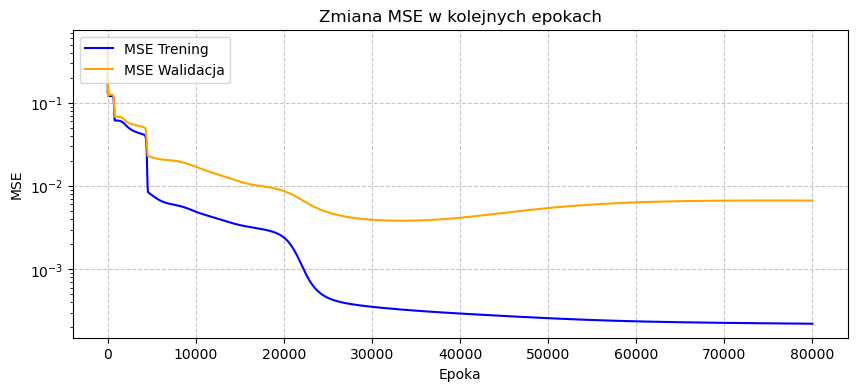

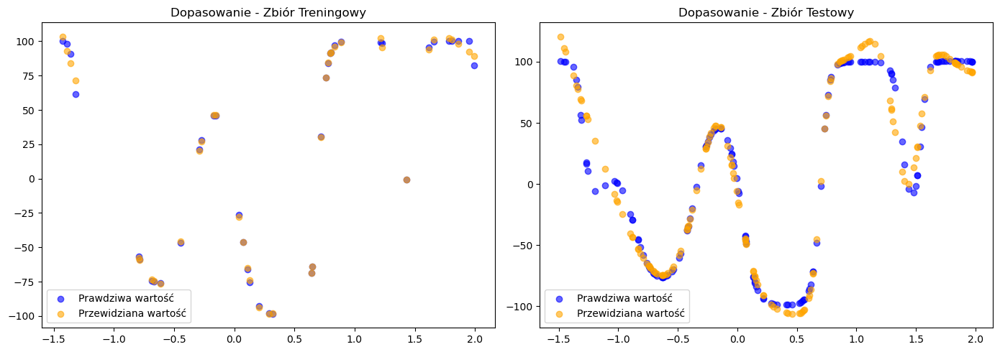

In [13]:
warstwa_1 = warstwa_liniowa(1, 64, 'xavier')
warstwa_2 = warstwa_liniowa(64, 64, 'xavier')
warstwa_3 = warstwa_liniowa(64, 1, 'xavier')
model = MLP((warstwa_1, tanh(), warstwa_2, tanh(), warstwa_3), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9, l2_lambda=0)
hist_train, hist_val, score = train(X_train, y_train, X_test, y_test, X_val, y_val, model, 80000, 64, funkcja_straty=MSE, regresja=True, test=True, patience=80000)

Krok     0 | MSE Trening: 8579.4934 | Walidacja:   0.1747 | Brak poprawy: 0/2000
Krok   100 | MSE Trening: 4801.6198 | Walidacja:   0.1270 | Brak poprawy: 65/2000
Krok   200 | MSE Trening: 4780.1485 | Walidacja:   0.1262 | Brak poprawy: 165/2000
Krok   300 | MSE Trening: 4674.7163 | Walidacja:   0.1237 | Brak poprawy: 265/2000
Krok   400 | MSE Trening: 3649.9172 | Walidacja:   0.0987 | Brak poprawy: 0/2000
Krok   500 | MSE Trening: 2433.1760 | Walidacja:   0.0685 | Brak poprawy: 20/2000
Krok   600 | MSE Trening: 2431.0923 | Walidacja:   0.0685 | Brak poprawy: 120/2000
Krok   700 | MSE Trening: 2428.5604 | Walidacja:   0.0685 | Brak poprawy: 220/2000
Krok   800 | MSE Trening: 2425.3239 | Walidacja:   0.0685 | Brak poprawy: 320/2000
Krok   900 | MSE Trening: 2421.0955 | Walidacja:   0.0685 | Brak poprawy: 420/2000
Krok  1000 | MSE Trening: 2415.4552 | Walidacja:   0.0684 | Brak poprawy: 520/2000
Krok  1100 | MSE Trening: 2407.7926 | Walidacja:   0.0684 | Brak poprawy: 0/2000
Krok  1200 |

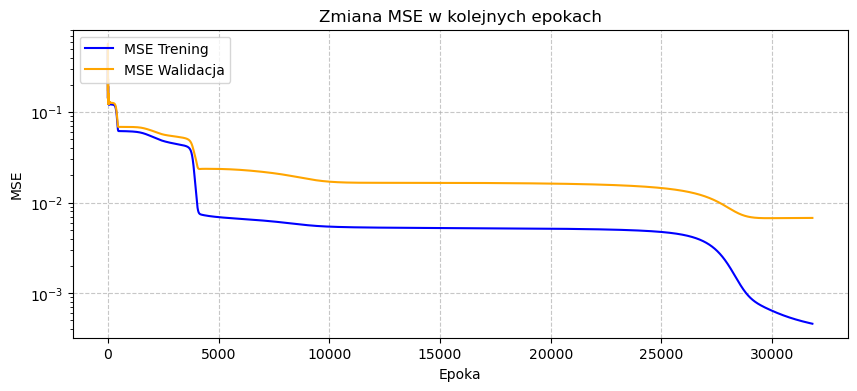

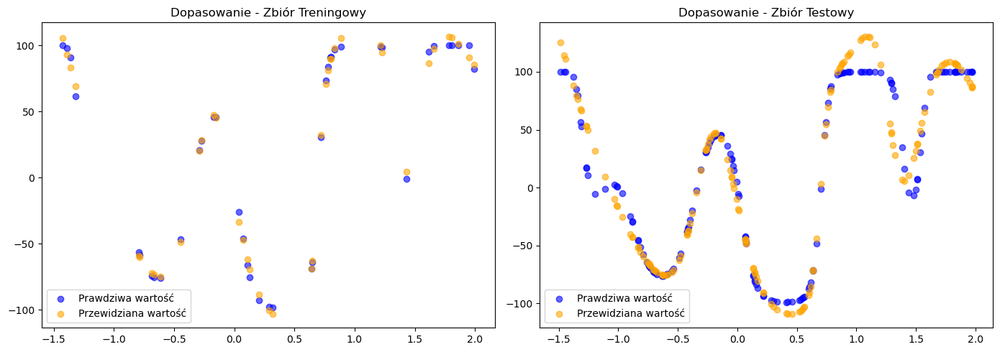

In [33]:
warstwa_1 = warstwa_liniowa(1, 64, 'xavier')
warstwa_2 = warstwa_liniowa(64, 64, 'xavier')
warstwa_3 = warstwa_liniowa(64, 1, 'xavier')
model = MLP((warstwa_1, tanh(), warstwa_2, tanh(), warstwa_3), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9, l2_lambda=0)
hist_train, hist_val, score = train(X_train, y_train, X_test, y_test, X_val, y_val, model, 80000, 64, funkcja_straty=MSE, regresja=True, test=True, patience=2000)

Krok     0 | MSE Trening: 6006.5914 | Walidacja:   0.1332 | Brak poprawy: 0/80000
Krok   100 | MSE Trening: 4815.5401 | Walidacja:   0.1274 | Brak poprawy: 71/80000
Krok   200 | MSE Trening: 4807.6802 | Walidacja:   0.1269 | Brak poprawy: 171/80000
Krok   300 | MSE Trening: 4800.4226 | Walidacja:   0.1268 | Brak poprawy: 271/80000
Krok   400 | MSE Trening: 4790.5650 | Walidacja:   0.1265 | Brak poprawy: 371/80000
Krok   500 | MSE Trening: 4769.3868 | Walidacja:   0.1260 | Brak poprawy: 471/80000
Krok   600 | MSE Trening: 4672.2166 | Walidacja:   0.1236 | Brak poprawy: 571/80000
Krok   700 | MSE Trening: 3691.3900 | Walidacja:   0.0998 | Brak poprawy: 0/80000
Krok   800 | MSE Trening: 2434.6420 | Walidacja:   0.0687 | Brak poprawy: 16/80000
Krok   900 | MSE Trening: 2432.6168 | Walidacja:   0.0687 | Brak poprawy: 116/80000
Krok  1000 | MSE Trening: 2430.1251 | Walidacja:   0.0687 | Brak poprawy: 216/80000
Krok  1100 | MSE Trening: 2426.9284 | Walidacja:   0.0686 | Brak poprawy: 316/8000

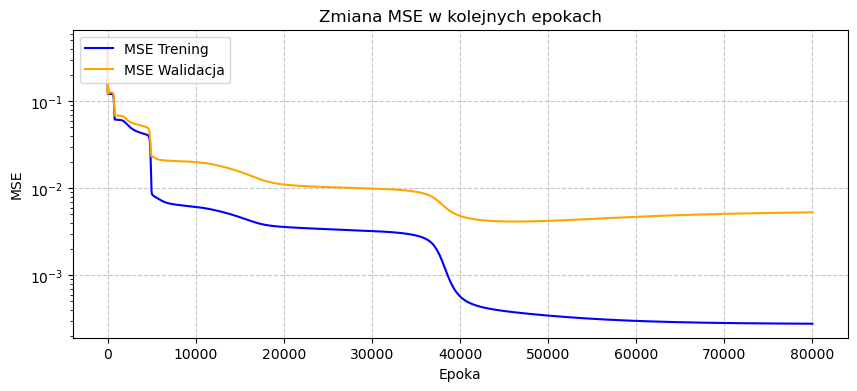

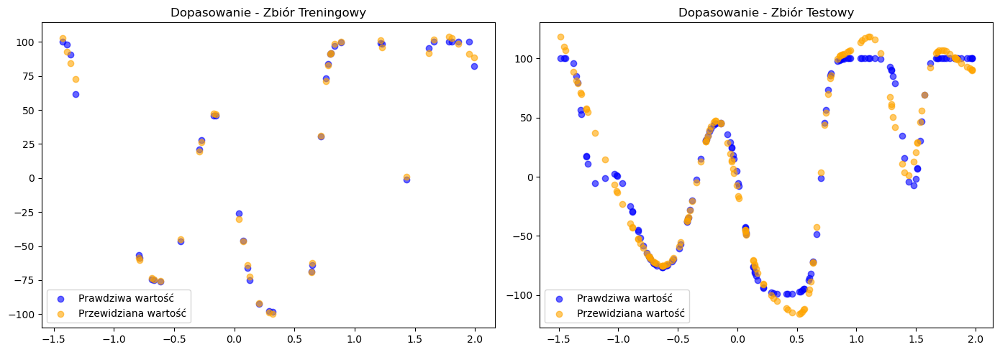

In [15]:
warstwa_1 = warstwa_liniowa(1, 64, 'xavier')
warstwa_2 = warstwa_liniowa(64, 64, 'xavier')
warstwa_3 = warstwa_liniowa(64, 1, 'xavier')
model = MLP((warstwa_1, tanh(), warstwa_2, tanh(), warstwa_3), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9, l2_lambda=0.00001)
hist_train, hist_val, score = train(X_train, y_train, X_test, y_test, X_val, y_val, model, 80000, 64, funkcja_straty=MSE, regresja=True, test=True, patience=80000)

Krok     0 | MSE Trening: 7240.2371 | Walidacja:   0.1535 | Brak poprawy: 0/2000
Krok   100 | MSE Trening: 4798.2105 | Walidacja:   0.1266 | Brak poprawy: 53/2000
Krok   200 | MSE Trening: 4785.6895 | Walidacja:   0.1264 | Brak poprawy: 153/2000
Krok   300 | MSE Trening: 4761.8309 | Walidacja:   0.1258 | Brak poprawy: 253/2000
Krok   400 | MSE Trening: 4668.0538 | Walidacja:   0.1235 | Brak poprawy: 353/2000
Krok   500 | MSE Trening: 3851.0709 | Walidacja:   0.1036 | Brak poprawy: 0/2000
Krok   600 | MSE Trening: 2430.4191 | Walidacja:   0.0680 | Brak poprawy: 6/2000
Krok   700 | MSE Trening: 2427.4175 | Walidacja:   0.0680 | Brak poprawy: 106/2000
Krok   800 | MSE Trening: 2423.8201 | Walidacja:   0.0679 | Brak poprawy: 0/2000
Krok   900 | MSE Trening: 2419.0668 | Walidacja:   0.0678 | Brak poprawy: 0/2000
Krok  1000 | MSE Trening: 2412.6180 | Walidacja:   0.0677 | Brak poprawy: 0/2000
Krok  1100 | MSE Trening: 2403.6620 | Walidacja:   0.0675 | Brak poprawy: 0/2000
Krok  1200 | MSE Tr

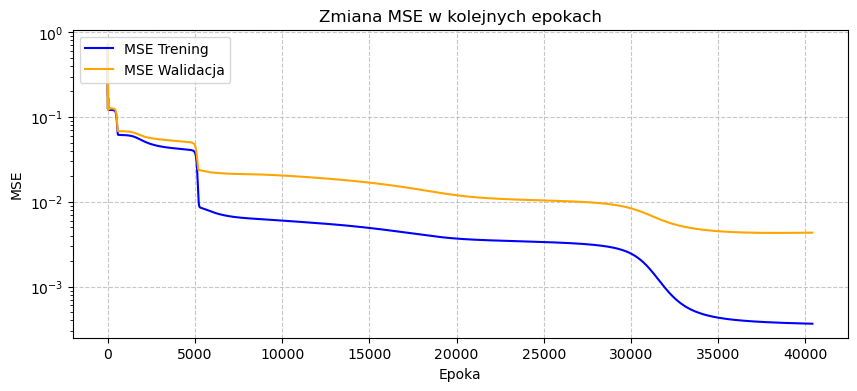

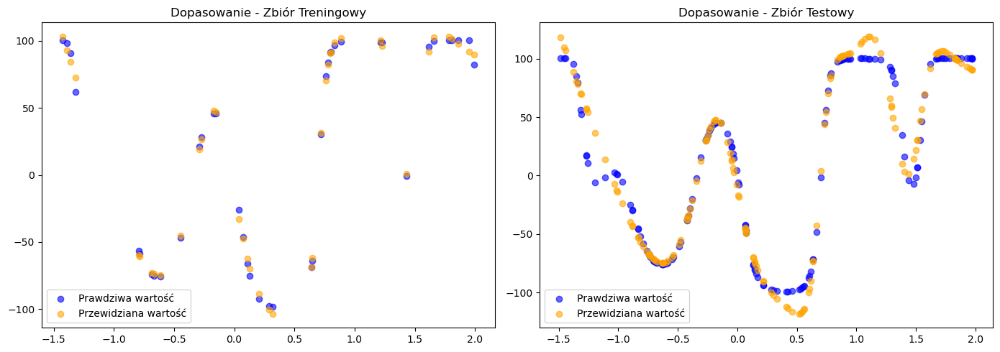

In [34]:
warstwa_1 = warstwa_liniowa(1, 64, 'xavier')
warstwa_2 = warstwa_liniowa(64, 64, 'xavier')
warstwa_3 = warstwa_liniowa(64, 1, 'xavier')
model = MLP((warstwa_1, tanh(), warstwa_2, tanh(), warstwa_3), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9, l2_lambda=0.00001)
hist_train, hist_val, score = train(X_train, y_train, X_test, y_test, X_val, y_val, model, 80000, 64, funkcja_straty=MSE, regresja=True, test=True, patience=2000)

# Dane rings5-sparse

In [35]:
rings5_sparse_test = pd.read_csv("mio1/classification/rings5-sparse-test.csv")
rings5_sparse_train = pd.read_csv("mio1/classification/rings5-sparse-training.csv")

X_train = rings5_sparse_train[['x', 'y']].to_numpy() 
y_train_etykiety = rings5_sparse_train[['c']].to_numpy().astype(int) 
X_test = rings5_sparse_test[['x', 'y']].to_numpy()
y_test_etykiety = rings5_sparse_test[['c']].to_numpy().astype(int)

X_test, X_val, y_test_etykiety, y_val_etykiety = train_test_split(X_test, y_test_etykiety, test_size=0.2, random_state=123)

liczba_klas = len(np.unique(y_train_etykiety))
y_train = to_one_hot(y_train_etykiety, liczba_klas)
y_test = to_one_hot(y_test_etykiety, liczba_klas)
y_val = to_one_hot(y_val_etykiety, liczba_klas)

Krok     0 | F1 Trening:   0.1391 | Walidacja: 655.9088 | Brak poprawy: 0/10000
Krok   100 | F1 Trening:   0.6939 | Walidacja: 328.2750 | Brak poprawy: 3/10000
Krok   200 | F1 Trening:   0.7851 | Walidacja: 281.3859 | Brak poprawy: 16/10000
Krok   300 | F1 Trening:   0.8252 | Walidacja: 303.4671 | Brak poprawy: 21/10000
Krok   400 | F1 Trening:   0.8573 | Walidacja: 231.3143 | Brak poprawy: 7/10000
Krok   500 | F1 Trening:   0.8923 | Walidacja: 230.7172 | Brak poprawy: 107/10000
Krok   600 | F1 Trening:   0.8230 | Walidacja: 270.8927 | Brak poprawy: 33/10000
Krok   700 | F1 Trening:   0.8786 | Walidacja: 238.1455 | Brak poprawy: 133/10000
Krok   800 | F1 Trening:   0.8667 | Walidacja: 267.3608 | Brak poprawy: 35/10000
Krok   900 | F1 Trening:   0.8430 | Walidacja: 240.7152 | Brak poprawy: 135/10000
Krok  1000 | F1 Trening:   0.8261 | Walidacja: 352.6885 | Brak poprawy: 235/10000
Krok  1100 | F1 Trening:   0.7474 | Walidacja: 315.7866 | Brak poprawy: 335/10000
Krok  1200 | F1 Trening:  

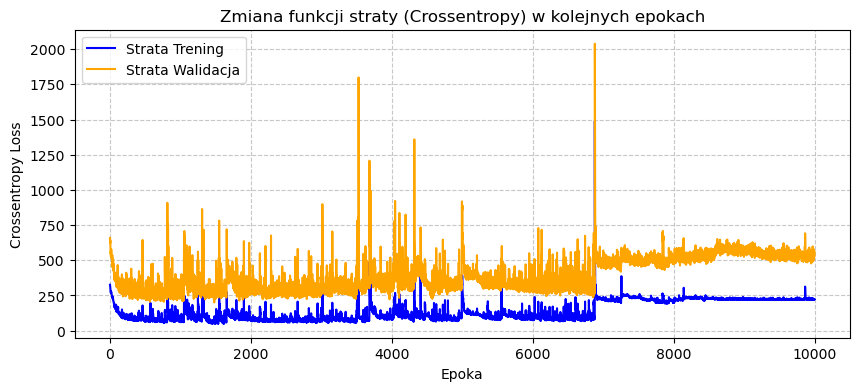

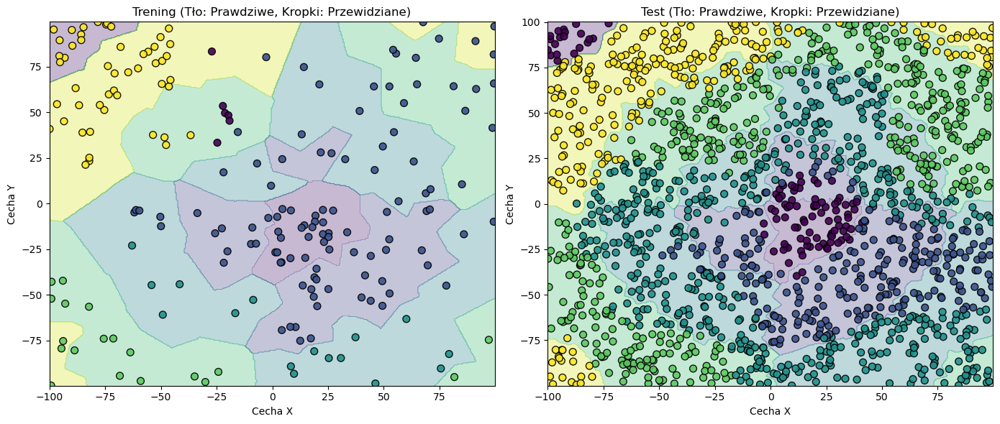

In [18]:
warstwa_1 = warstwa_liniowa(2, 10, 'xavier')
warstwa_2 = warstwa_liniowa(10, 5, 'xavier')
warstwa_3 = warstwa_liniowa(5, liczba_klas, 'xavier')
model = MLP((warstwa_1, tanh(), warstwa_2, tanh(), warstwa_3, softmax()), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9, l2_lambda=0)
hist_train, hist_val, score = train(X_train, y_train, X_test, y_test, X_val, y_val, model, 10000, 64, funkcja_straty=Crossentropy, regresja=False, test=True, patience=10000)

Krok     0 | F1 Trening:   0.1754 | Walidacja: 640.1339 | Brak poprawy: 0/400
Krok   100 | F1 Trening:   0.7213 | Walidacja: 312.4014 | Brak poprawy: 1/400
Krok   200 | F1 Trening:   0.8408 | Walidacja: 247.3982 | Brak poprawy: 9/400
Krok   300 | F1 Trening:   0.7753 | Walidacja: 257.4568 | Brak poprawy: 11/400
Krok   400 | F1 Trening:   0.8262 | Walidacja: 252.8652 | Brak poprawy: 32/400
Krok   500 | F1 Trening:   0.8795 | Walidacja: 249.3170 | Brak poprawy: 132/400
Krok   600 | F1 Trening:   0.8788 | Walidacja: 231.6674 | Brak poprawy: 232/400
Krok   700 | F1 Trening:   0.9149 | Walidacja: 195.5092 | Brak poprawy: 20/400
Krok   800 | F1 Trening:   0.8262 | Walidacja: 315.8994 | Brak poprawy: 5/400
Krok   900 | F1 Trening:   0.9139 | Walidacja: 225.2923 | Brak poprawy: 73/400
Krok  1000 | F1 Trening:   0.8774 | Walidacja: 266.2372 | Brak poprawy: 22/400
Krok  1100 | F1 Trening:   0.9247 | Walidacja: 211.3403 | Brak poprawy: 122/400
Krok  1200 | F1 Trening:   0.8638 | Walidacja: 313.99

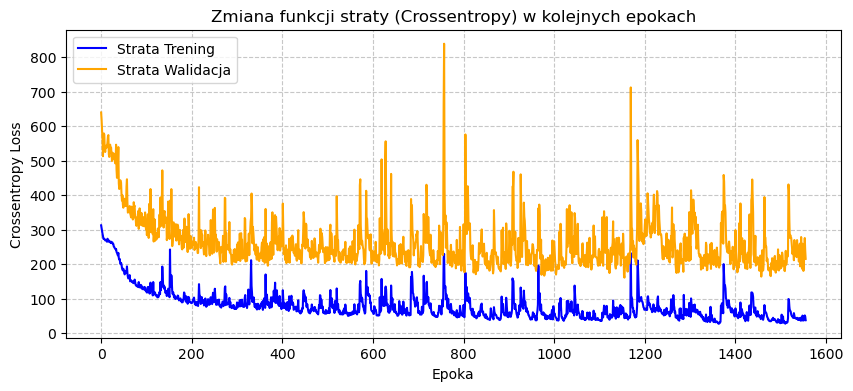

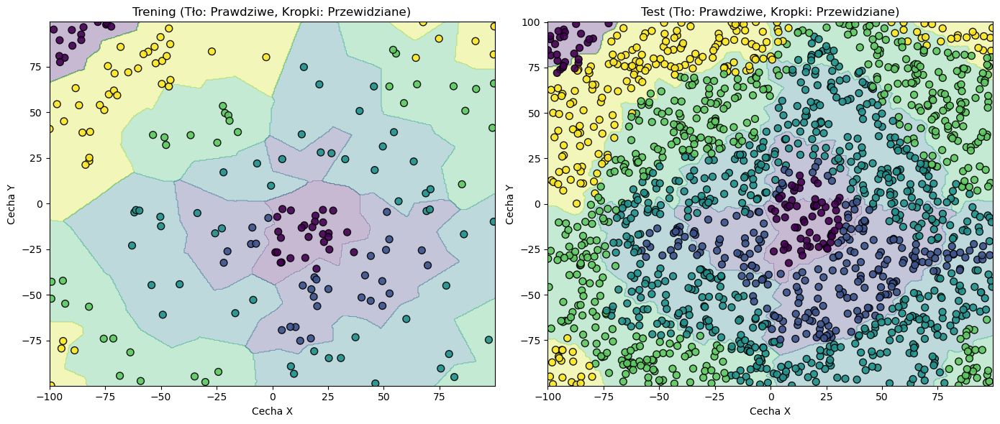

In [19]:
warstwa_1 = warstwa_liniowa(2, 10, 'xavier')
warstwa_2 = warstwa_liniowa(10, 5, 'xavier')
warstwa_3 = warstwa_liniowa(5, liczba_klas, 'xavier')
model = MLP((warstwa_1, tanh(), warstwa_2, tanh(), warstwa_3, softmax()), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9, l2_lambda=0)
hist_train, hist_val, score = train(X_train, y_train, X_test, y_test, X_val, y_val, model, 10000, 64, funkcja_straty=Crossentropy, regresja=False, test=True, patience=400)

Krok     0 | F1 Trening:   0.0871 | Walidacja: 633.9720 | Brak poprawy: 0/10000
Krok   100 | F1 Trening:   0.6788 | Walidacja: 331.8327 | Brak poprawy: 5/10000
Krok   200 | F1 Trening:   0.7882 | Walidacja: 304.7010 | Brak poprawy: 14/10000
Krok   300 | F1 Trening:   0.8189 | Walidacja: 270.8442 | Brak poprawy: 21/10000
Krok   400 | F1 Trening:   0.8812 | Walidacja: 202.0180 | Brak poprawy: 13/10000
Krok   500 | F1 Trening:   0.8521 | Walidacja: 328.5935 | Brak poprawy: 91/10000
Krok   600 | F1 Trening:   0.8455 | Walidacja: 271.2585 | Brak poprawy: 4/10000
Krok   700 | F1 Trening:   0.9138 | Walidacja: 210.7222 | Brak poprawy: 104/10000
Krok   800 | F1 Trening:   0.8988 | Walidacja: 208.3479 | Brak poprawy: 204/10000
Krok   900 | F1 Trening:   0.9096 | Walidacja: 263.1742 | Brak poprawy: 304/10000
Krok  1000 | F1 Trening:   0.7660 | Walidacja: 322.1618 | Brak poprawy: 404/10000
Krok  1100 | F1 Trening:   0.7553 | Walidacja: 383.7090 | Brak poprawy: 504/10000
Krok  1200 | F1 Trening:  

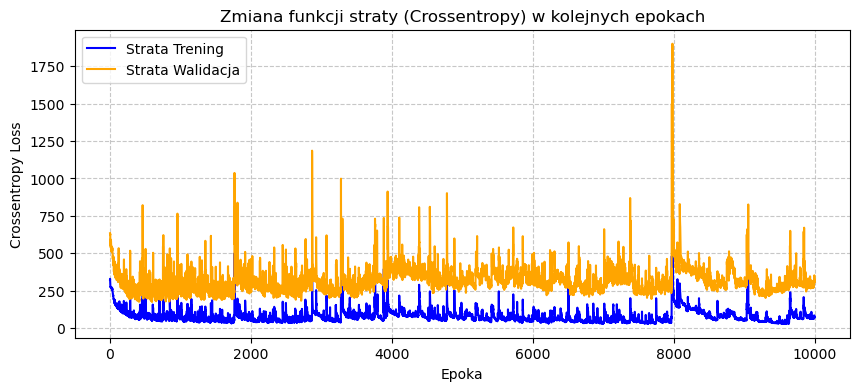

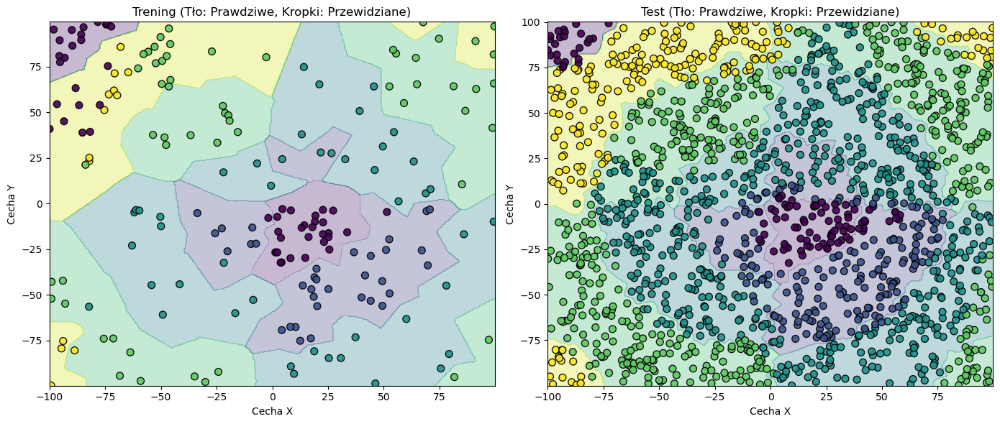

In [39]:
warstwa_1 = warstwa_liniowa(2, 10, 'xavier')
warstwa_2 = warstwa_liniowa(10, 5, 'xavier')
warstwa_3 = warstwa_liniowa(5, liczba_klas, 'xavier')
model = MLP((warstwa_1, tanh(), warstwa_2, tanh(), warstwa_3, softmax()), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9, l2_lambda=0.00001)
hist_train, hist_val, score = train(X_train, y_train, X_test, y_test, X_val, y_val, model, 10000, 64, funkcja_straty=Crossentropy, regresja=False, test=True, patience=10000)

Krok     0 | F1 Trening:   0.0638 | Walidacja: 656.6924 | Brak poprawy: 0/400
Krok   100 | F1 Trening:   0.7111 | Walidacja: 350.2269 | Brak poprawy: 11/400
Krok   200 | F1 Trening:   0.7616 | Walidacja: 296.5703 | Brak poprawy: 9/400
Krok   300 | F1 Trening:   0.7596 | Walidacja: 314.0987 | Brak poprawy: 18/400
Krok   400 | F1 Trening:   0.8856 | Walidacja: 215.8214 | Brak poprawy: 118/400
Krok   500 | F1 Trening:   0.8471 | Walidacja: 242.2037 | Brak poprawy: 90/400
Krok   600 | F1 Trening:   0.8895 | Walidacja: 224.6083 | Brak poprawy: 13/400
Krok   700 | F1 Trening:   0.8847 | Walidacja: 194.7566 | Brak poprawy: 79/400
Krok   800 | F1 Trening:   0.8745 | Walidacja: 246.0151 | Brak poprawy: 179/400
Krok   900 | F1 Trening:   0.8947 | Walidacja: 204.6364 | Brak poprawy: 7/400
Krok  1000 | F1 Trening:   0.9026 | Walidacja: 207.2147 | Brak poprawy: 43/400
Krok  1100 | F1 Trening:   0.8597 | Walidacja: 295.7157 | Brak poprawy: 27/400
Krok  1200 | F1 Trening:   0.8370 | Walidacja: 293.23

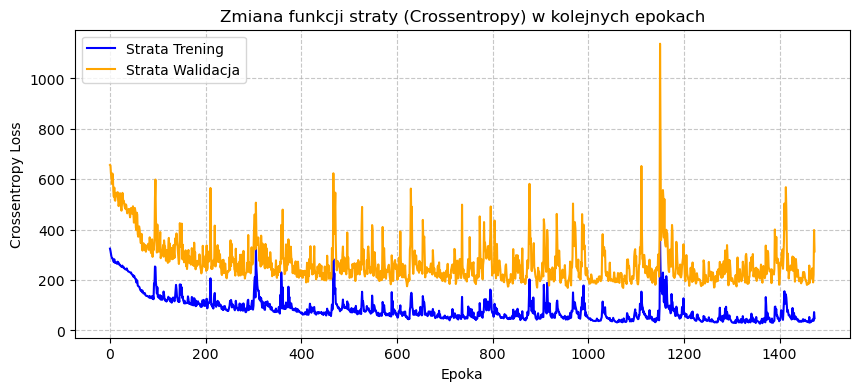

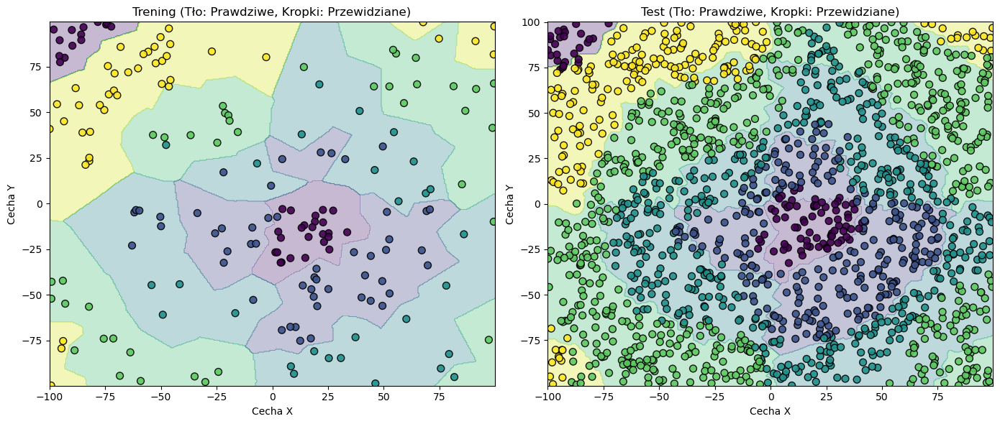

In [21]:
warstwa_1 = warstwa_liniowa(2, 10, 'xavier')
warstwa_2 = warstwa_liniowa(10, 5, 'xavier')
warstwa_3 = warstwa_liniowa(5, liczba_klas, 'xavier')
model = MLP((warstwa_1, tanh(), warstwa_2, tanh(), warstwa_3, softmax()), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9, l2_lambda=0.00001)
hist_train, hist_val, score = train(X_train, y_train, X_test, y_test, X_val, y_val, model, 10000, 64, funkcja_straty=Crossentropy, regresja=False, test=True, patience=400)

# Dane rings3-balance

In [40]:
rings3_balance_test = pd.read_csv("mio1/classification/rings3-balance-test.csv")
rings3_balance_train = pd.read_csv("mio1/classification/rings3-balance-training.csv")

X_train = rings3_balance_train[['x', 'y']].to_numpy() 
y_train_etykiety = rings3_balance_train[['c']].to_numpy().astype(int) 
X_test = rings3_balance_test[['x', 'y']].to_numpy()
y_test_etykiety = rings3_balance_test[['c']].to_numpy().astype(int)

X_test, X_val, y_test_etykiety, y_val_etykiety = train_test_split(X_test, y_test_etykiety, test_size=0.2, random_state=123)

liczba_klas = len(np.unique(y_train_etykiety))
y_train = to_one_hot(y_train_etykiety, liczba_klas)
y_test = to_one_hot(y_test_etykiety, liczba_klas)
y_val = to_one_hot(y_val_etykiety, liczba_klas)

Krok     0 | F1 Trening:   0.4347 | Walidacja: 802.0718 | Brak poprawy: 0/10000
Krok   100 | F1 Trening:   0.8364 | Walidacja: 313.7735 | Brak poprawy: 6/10000
Krok   200 | F1 Trening:   0.8710 | Walidacja: 297.3177 | Brak poprawy: 10/10000
Krok   300 | F1 Trening:   0.8512 | Walidacja: 277.3508 | Brak poprawy: 110/10000
Krok   400 | F1 Trening:   0.8540 | Walidacja: 309.6778 | Brak poprawy: 210/10000
Krok   500 | F1 Trening:   0.8422 | Walidacja: 324.8830 | Brak poprawy: 35/10000
Krok   600 | F1 Trening:   0.8968 | Walidacja: 269.8600 | Brak poprawy: 135/10000
Krok   700 | F1 Trening:   0.8964 | Walidacja: 261.9111 | Brak poprawy: 235/10000
Krok   800 | F1 Trening:   0.8511 | Walidacja: 300.0704 | Brak poprawy: 14/10000
Krok   900 | F1 Trening:   0.8768 | Walidacja: 218.0399 | Brak poprawy: 60/10000
Krok  1000 | F1 Trening:   0.9086 | Walidacja: 242.5105 | Brak poprawy: 3/10000
Krok  1100 | F1 Trening:   0.8722 | Walidacja: 395.8113 | Brak poprawy: 103/10000
Krok  1200 | F1 Trening:  

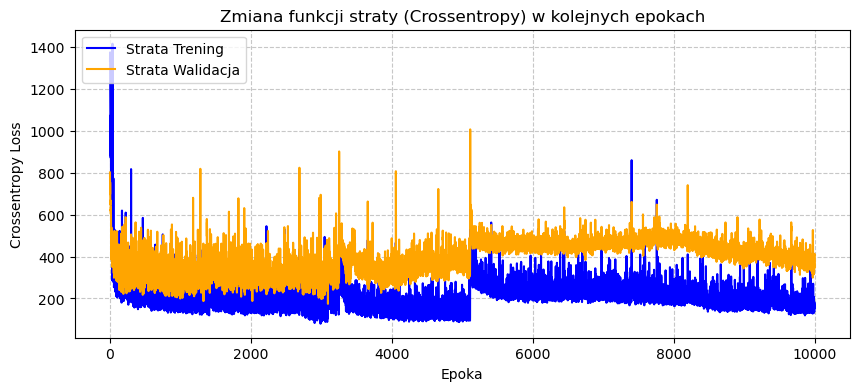

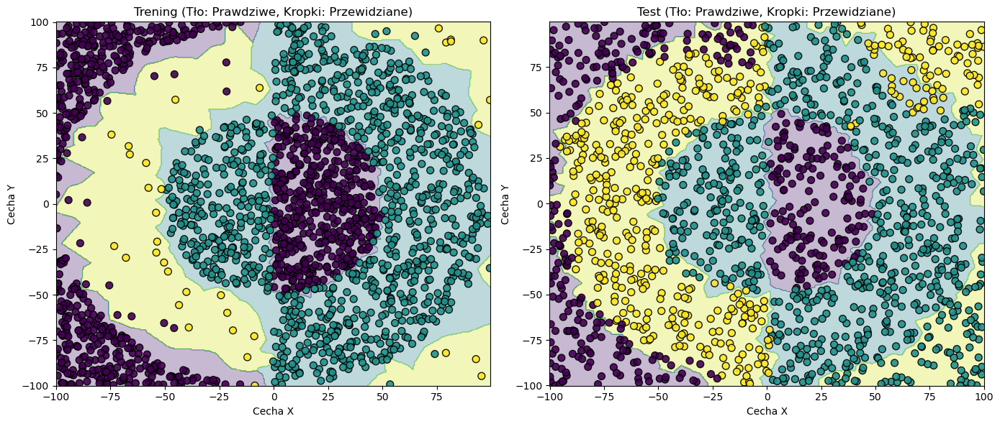

In [23]:
warstwa_1 = warstwa_liniowa(2, 10, 'xavier')
warstwa_2 = warstwa_liniowa(10, 5, 'xavier')
warstwa_3 = warstwa_liniowa(5, liczba_klas, 'xavier')
model = MLP((warstwa_1, tanh(), warstwa_2, tanh(), warstwa_3, softmax()), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9, l2_lambda=0)
hist_train, hist_val, score = train(X_train, y_train, X_test, y_test, X_val, y_val, model, 10000, 64, funkcja_straty=Crossentropy, regresja=False, test=True, patience=10000)

Krok     0 | F1 Trening:   0.4536 | Walidacja: 770.8903 | Brak poprawy: 0/400
Krok   100 | F1 Trening:   0.8399 | Walidacja: 362.2070 | Brak poprawy: 8/400
Krok   200 | F1 Trening:   0.8198 | Walidacja: 274.8798 | Brak poprawy: 30/400
Krok   300 | F1 Trening:   0.8774 | Walidacja: 371.2100 | Brak poprawy: 130/400
Krok   400 | F1 Trening:   0.8962 | Walidacja: 326.7034 | Brak poprawy: 4/400
Krok   500 | F1 Trening:   0.8935 | Walidacja: 259.7289 | Brak poprawy: 89/400
Krok   600 | F1 Trening:   0.8972 | Walidacja: 352.3865 | Brak poprawy: 189/400
Krok   700 | F1 Trening:   0.9112 | Walidacja: 299.3753 | Brak poprawy: 289/400
Krok   800 | F1 Trening:   0.8977 | Walidacja: 272.0400 | Brak poprawy: 389/400

[ EARLY STOPPING ] Przerwano uczenie w epoce 811! Brak poprawy od 400 epok.
--------------------------------------------------
Wczytano wagi z najlepszej epoki 811 (Strata Walidacyjna: 185.8802).
F1 treningowe FINALNE: 0.9078
F1 testowe FINALNE: 0.8394


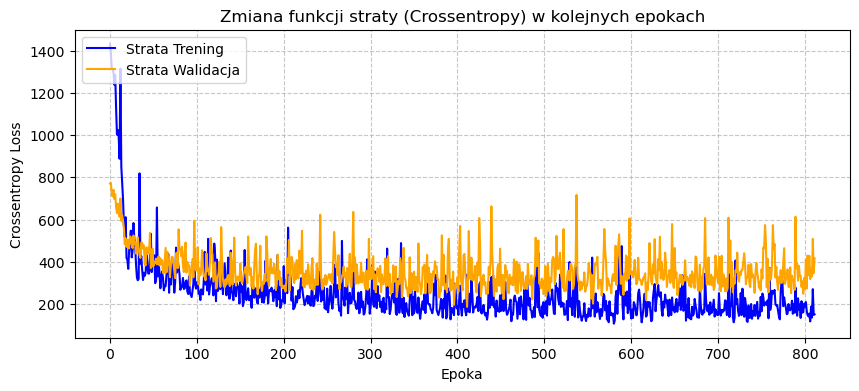

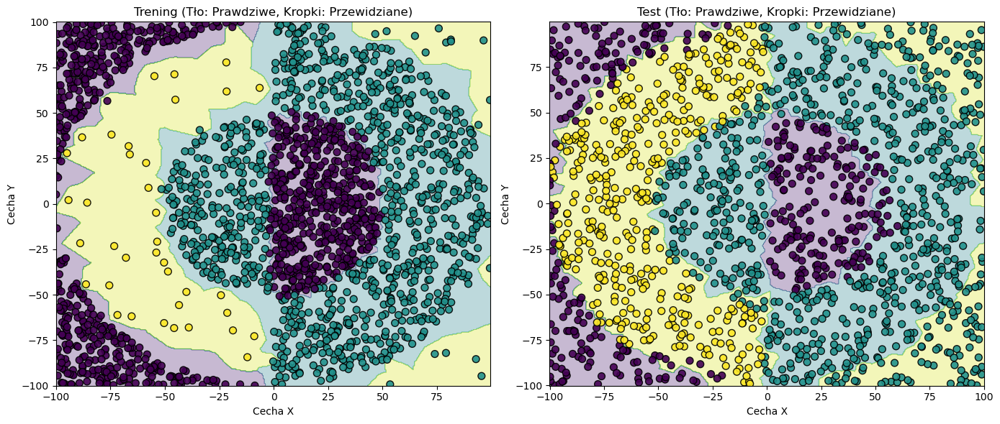

In [24]:
warstwa_1 = warstwa_liniowa(2, 10, 'xavier')
warstwa_2 = warstwa_liniowa(10, 5, 'xavier')
warstwa_3 = warstwa_liniowa(5, liczba_klas, 'xavier')
model = MLP((warstwa_1, tanh(), warstwa_2, tanh(), warstwa_3, softmax()), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9, l2_lambda=0)
hist_train, hist_val, score = train(X_train, y_train, X_test, y_test, X_val, y_val, model, 10000, 64, funkcja_straty=Crossentropy, regresja=False, test=True, patience=400)

Krok     0 | F1 Trening:   0.4317 | Walidacja: 812.7345 | Brak poprawy: 0/10000
Krok   100 | F1 Trening:   0.7982 | Walidacja: 304.8857 | Brak poprawy: 42/10000
Krok   200 | F1 Trening:   0.8922 | Walidacja: 295.1164 | Brak poprawy: 3/10000
Krok   300 | F1 Trening:   0.8933 | Walidacja: 418.4761 | Brak poprawy: 58/10000
Krok   400 | F1 Trening:   0.8925 | Walidacja: 360.6494 | Brak poprawy: 158/10000
Krok   500 | F1 Trening:   0.9620 | Walidacja: 172.2196 | Brak poprawy: 37/10000
Krok   600 | F1 Trening:   0.9158 | Walidacja: 193.3605 | Brak poprawy: 137/10000
Krok   700 | F1 Trening:   0.8975 | Walidacja: 255.2490 | Brak poprawy: 237/10000
Krok   800 | F1 Trening:   0.9798 | Walidacja: 212.8152 | Brak poprawy: 44/10000
Krok   900 | F1 Trening:   0.8244 | Walidacja: 419.3312 | Brak poprawy: 144/10000
Krok  1000 | F1 Trening:   0.9053 | Walidacja: 417.4672 | Brak poprawy: 244/10000
Krok  1100 | F1 Trening:   0.9467 | Walidacja: 287.9271 | Brak poprawy: 344/10000
Krok  1200 | F1 Trening:

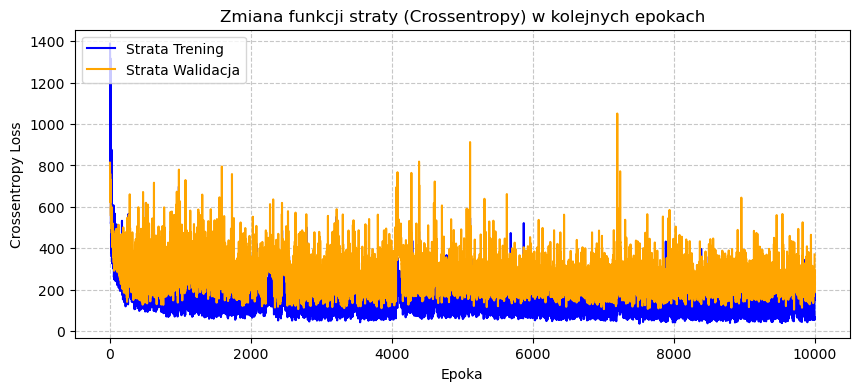

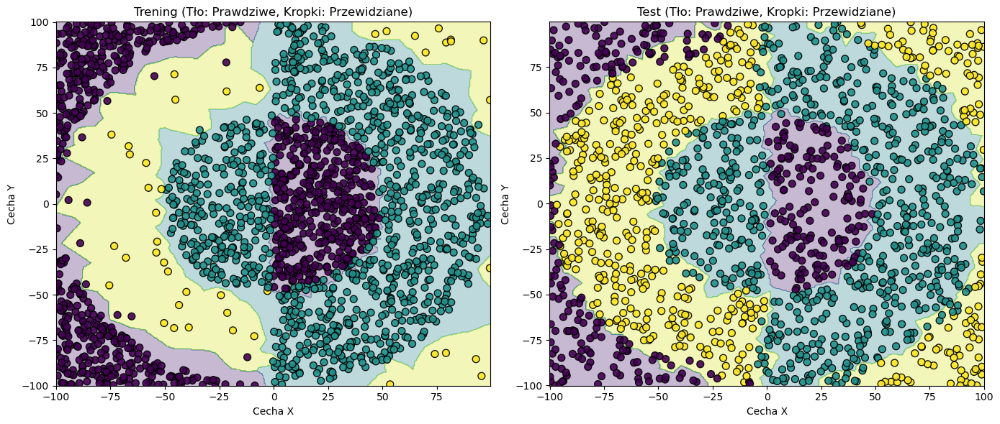

In [25]:
warstwa_1 = warstwa_liniowa(2, 10, 'xavier')
warstwa_2 = warstwa_liniowa(10, 5, 'xavier')
warstwa_3 = warstwa_liniowa(5, liczba_klas, 'xavier')
model = MLP((warstwa_1, tanh(), warstwa_2, tanh(), warstwa_3, softmax()), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9, l2_lambda=0.00001)
hist_train, hist_val, score = train(X_train, y_train, X_test, y_test, X_val, y_val, model, 10000, 64, funkcja_straty=Crossentropy, regresja=False, test=True, patience=10000)

Krok     0 | F1 Trening:   0.4457 | Walidacja: 807.1990 | Brak poprawy: 0/400
Krok   100 | F1 Trening:   0.8675 | Walidacja: 269.3580 | Brak poprawy: 0/400
Krok   200 | F1 Trening:   0.8674 | Walidacja: 334.4633 | Brak poprawy: 36/400
Krok   300 | F1 Trening:   0.8615 | Walidacja: 294.5765 | Brak poprawy: 136/400
Krok   400 | F1 Trening:   0.9013 | Walidacja: 290.5386 | Brak poprawy: 236/400
Krok   500 | F1 Trening:   0.9131 | Walidacja: 298.7371 | Brak poprawy: 59/400
Krok   600 | F1 Trening:   0.8684 | Walidacja: 334.0423 | Brak poprawy: 159/400
Krok   700 | F1 Trening:   0.8661 | Walidacja: 317.5760 | Brak poprawy: 259/400
Krok   800 | F1 Trening:   0.8653 | Walidacja: 379.4129 | Brak poprawy: 359/400

[ EARLY STOPPING ] Przerwano uczenie w epoce 841! Brak poprawy od 400 epok.
--------------------------------------------------
Wczytano wagi z najlepszej epoki 841 (Strata Walidacyjna: 229.3994).
F1 treningowe FINALNE: 0.8814
F1 testowe FINALNE: 0.8290


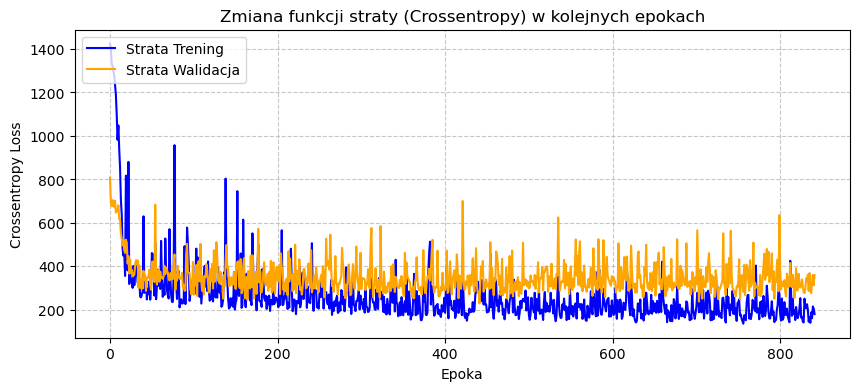

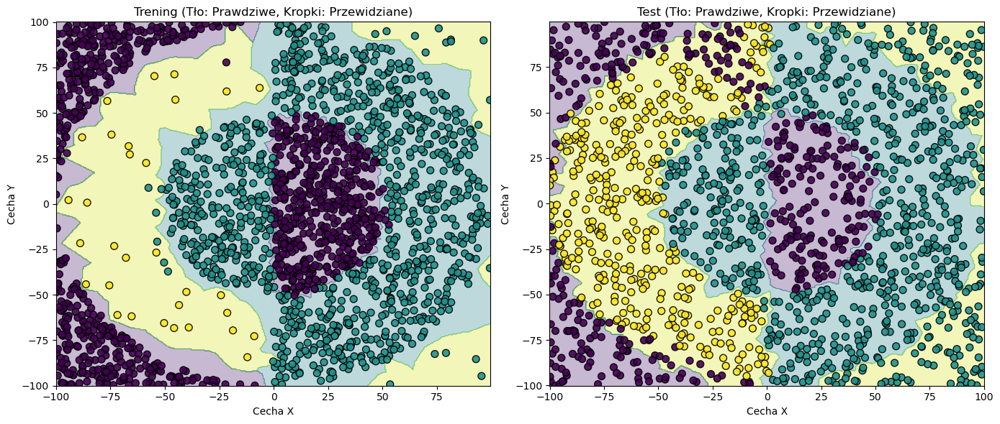

In [26]:
warstwa_1 = warstwa_liniowa(2, 10, 'xavier')
warstwa_2 = warstwa_liniowa(10, 5, 'xavier')
warstwa_3 = warstwa_liniowa(5, liczba_klas, 'xavier')
model = MLP((warstwa_1, tanh(), warstwa_2, tanh(), warstwa_3, softmax()), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9, l2_lambda=0.00001)
hist_train, hist_val, score = train(X_train, y_train, X_test, y_test, X_val, y_val, model, 10000, 64, funkcja_straty=Crossentropy, regresja=False, test=True, patience=400)

# Dane xor3-balance

In [41]:
xor3_balance_test = pd.read_csv("mio1/classification/xor3-balance-test.csv")
xor3_balance_train = pd.read_csv("mio1/classification/xor3-balance-training.csv")

X_train = xor3_balance_train[['x', 'y']].to_numpy() 
y_train_etykiety = xor3_balance_train[['c']].to_numpy().astype(int) 
X_test = xor3_balance_test[['x', 'y']].to_numpy()
y_test_etykiety = xor3_balance_test[['c']].to_numpy().astype(int)

X_test, X_val, y_test_etykiety, y_val_etykiety = train_test_split(X_test, y_test_etykiety, test_size=0.2, random_state=123)

liczba_klas = len(np.unique(y_train_etykiety))
y_train = to_one_hot(y_train_etykiety, liczba_klas)
y_test = to_one_hot(y_test_etykiety, liczba_klas)
y_val = to_one_hot(y_val_etykiety, liczba_klas)

Krok     0 | F1 Trening:   0.4878 | Walidacja: 363.2873 | Brak poprawy: 0/10000
Krok   100 | F1 Trening:   0.4878 | Walidacja: 251.3068 | Brak poprawy: 18/10000
Krok   200 | F1 Trening:   0.4878 | Walidacja: 229.8435 | Brak poprawy: 118/10000
Krok   300 | F1 Trening:   0.4878 | Walidacja: 238.7083 | Brak poprawy: 218/10000
Krok   400 | F1 Trening:   0.8450 | Walidacja: 151.3733 | Brak poprawy: 2/10000
Krok   500 | F1 Trening:   0.8780 | Walidacja: 132.3991 | Brak poprawy: 34/10000
Krok   600 | F1 Trening:   0.9151 | Walidacja: 121.2336 | Brak poprawy: 41/10000
Krok   700 | F1 Trening:   0.8690 | Walidacja: 125.1262 | Brak poprawy: 23/10000
Krok   800 | F1 Trening:   0.9288 | Walidacja: 101.9389 | Brak poprawy: 123/10000
Krok   900 | F1 Trening:   0.9355 | Walidacja: 104.5558 | Brak poprawy: 16/10000
Krok  1000 | F1 Trening:   0.9355 | Walidacja: 100.8270 | Brak poprawy: 116/10000
Krok  1100 | F1 Trening:   0.9221 | Walidacja: 102.1116 | Brak poprawy: 64/10000
Krok  1200 | F1 Trening:  

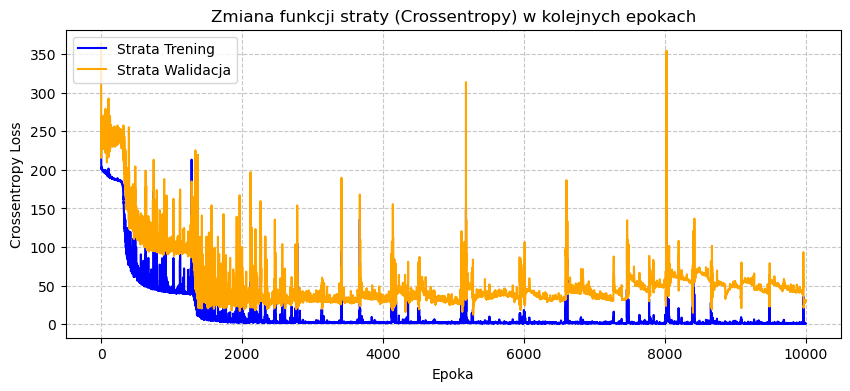

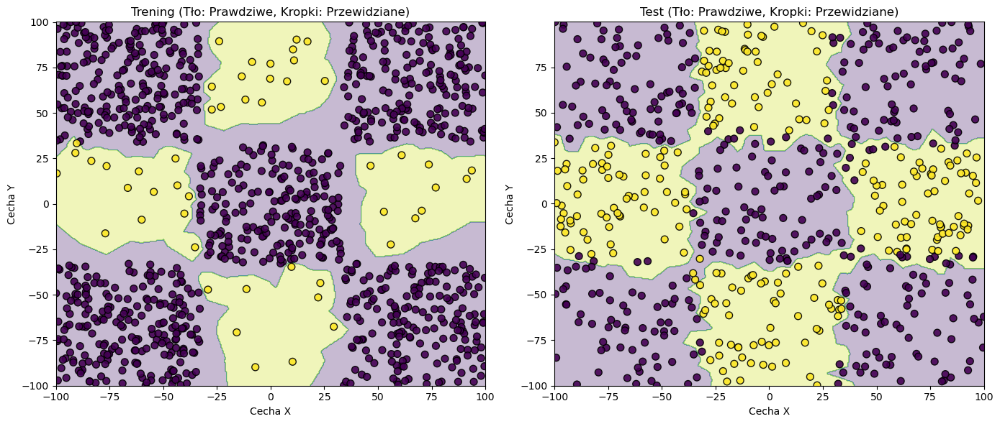

In [28]:
warstwa_1 = warstwa_liniowa(2, 10, 'xavier')
warstwa_2 = warstwa_liniowa(10, 5, 'xavier')
warstwa_3 = warstwa_liniowa(5, liczba_klas, 'xavier')
model = MLP((warstwa_1, tanh(), warstwa_2, tanh(), warstwa_3, softmax()), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9, l2_lambda=0)
hist_train, hist_val, score = train(X_train, y_train, X_test, y_test, X_val, y_val, model, 10000, 64, funkcja_straty=Crossentropy, regresja=False, test=True, patience=10000)

Krok     0 | F1 Trening:   0.4878 | Walidacja: 274.9930 | Brak poprawy: 0/400
Krok   100 | F1 Trening:   0.4878 | Walidacja: 225.1321 | Brak poprawy: 13/400
Krok   200 | F1 Trening:   0.4878 | Walidacja: 237.6642 | Brak poprawy: 113/400
Krok   300 | F1 Trening:   0.7112 | Walidacja: 181.2560 | Brak poprawy: 3/400
Krok   400 | F1 Trening:   0.9394 | Walidacja:  61.5118 | Brak poprawy: 25/400
Krok   500 | F1 Trening:   0.9606 | Walidacja:  47.5964 | Brak poprawy: 10/400
Krok   600 | F1 Trening:   0.9782 | Walidacja:  36.6116 | Brak poprawy: 19/400
Krok   700 | F1 Trening:   0.9790 | Walidacja:  24.5385 | Brak poprawy: 11/400
Krok   800 | F1 Trening:   1.0000 | Walidacja:  33.9496 | Brak poprawy: 111/400
Krok   900 | F1 Trening:   0.9947 | Walidacja:  33.6365 | Brak poprawy: 211/400
Krok  1000 | F1 Trening:   0.9893 | Walidacja:  39.0371 | Brak poprawy: 311/400

[ EARLY STOPPING ] Przerwano uczenie w epoce 1089! Brak poprawy od 400 epok.
--------------------------------------------------


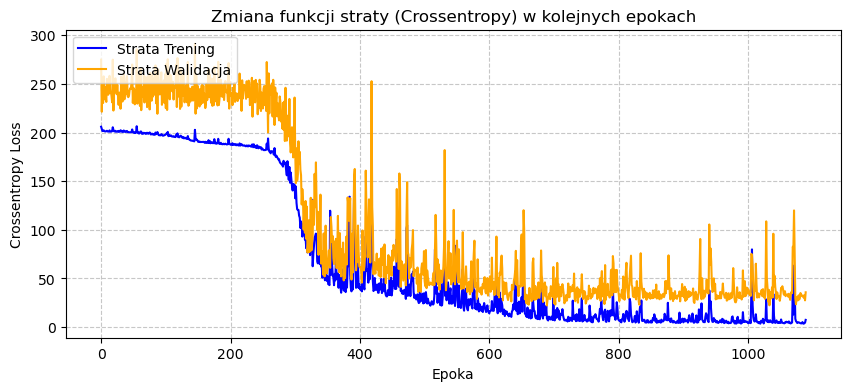

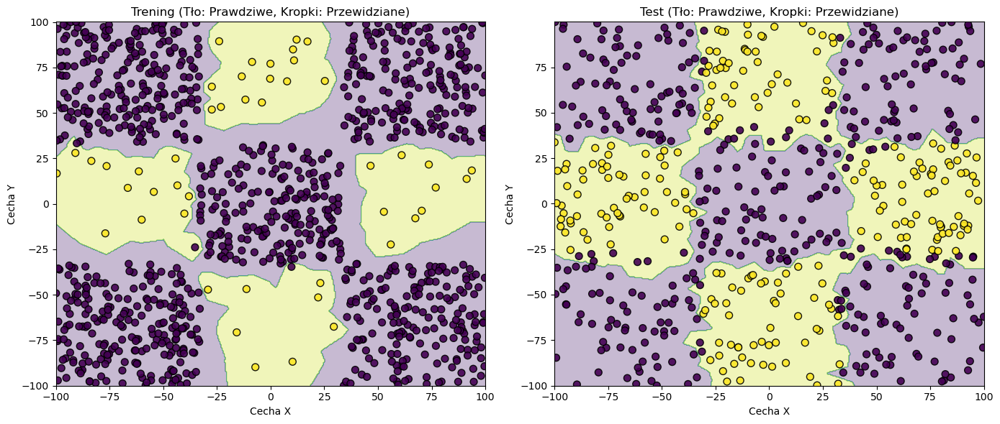

In [29]:
warstwa_1 = warstwa_liniowa(2, 10, 'xavier')
warstwa_2 = warstwa_liniowa(10, 5, 'xavier')
warstwa_3 = warstwa_liniowa(5, liczba_klas, 'xavier')
model = MLP((warstwa_1, tanh(), warstwa_2, tanh(), warstwa_3, softmax()), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9, l2_lambda=0)
hist_train, hist_val, score = train(X_train, y_train, X_test, y_test, X_val, y_val, model, 10000, 64, funkcja_straty=Crossentropy, regresja=False, test=True, patience=400)

Krok     0 | F1 Trening:   0.4878 | Walidacja: 335.5189 | Brak poprawy: 0/10000
Krok   100 | F1 Trening:   0.4878 | Walidacja: 227.9559 | Brak poprawy: 99/10000
Krok   200 | F1 Trening:   0.4878 | Walidacja: 245.0595 | Brak poprawy: 199/10000
Krok   300 | F1 Trening:   0.5267 | Walidacja: 270.6403 | Brak poprawy: 299/10000
Krok   400 | F1 Trening:   0.9008 | Walidacja:  68.7816 | Brak poprawy: 7/10000
Krok   500 | F1 Trening:   0.9666 | Walidacja:  33.4035 | Brak poprawy: 8/10000
Krok   600 | F1 Trening:   0.9893 | Walidacja:  27.2729 | Brak poprawy: 48/10000
Krok   700 | F1 Trening:   0.9893 | Walidacja:  25.2036 | Brak poprawy: 148/10000
Krok   800 | F1 Trening:   0.9947 | Walidacja:  27.6663 | Brak poprawy: 248/10000
Krok   900 | F1 Trening:   0.9947 | Walidacja:  38.1020 | Brak poprawy: 18/10000
Krok  1000 | F1 Trening:   0.9893 | Walidacja:  32.7093 | Brak poprawy: 118/10000
Krok  1100 | F1 Trening:   0.9947 | Walidacja:  29.7964 | Brak poprawy: 218/10000
Krok  1200 | F1 Trening: 

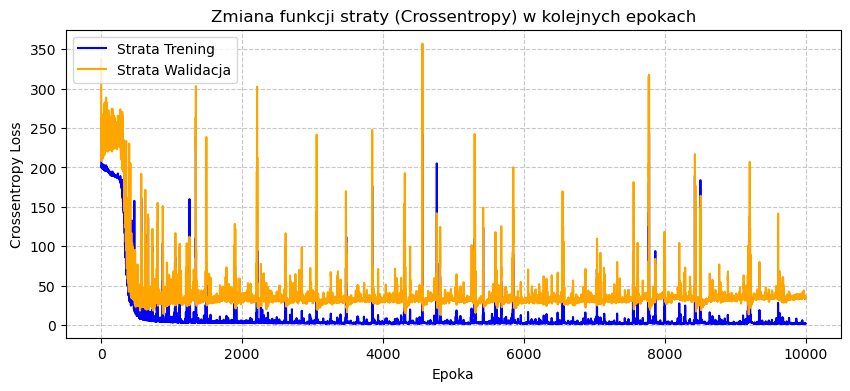

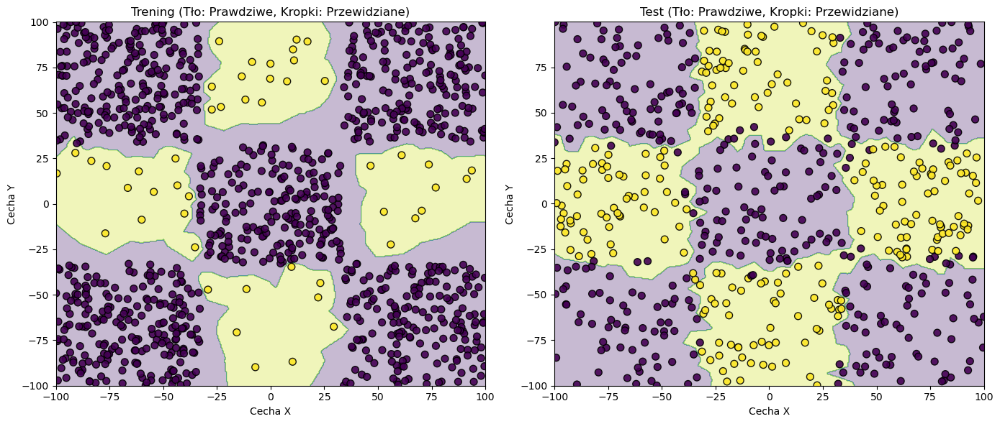

In [30]:
warstwa_1 = warstwa_liniowa(2, 10, 'xavier')
warstwa_2 = warstwa_liniowa(10, 5, 'xavier')
warstwa_3 = warstwa_liniowa(5, liczba_klas, 'xavier')
model = MLP((warstwa_1, tanh(), warstwa_2, tanh(), warstwa_3, softmax()), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9, l2_lambda=0.00001)
hist_train, hist_val, score = train(X_train, y_train, X_test, y_test, X_val, y_val, model, 10000, 64, funkcja_straty=Crossentropy, regresja=False, test=True, patience=10000)

Krok     0 | F1 Trening:   0.4878 | Walidacja: 310.3720 | Brak poprawy: 0/400
Krok   100 | F1 Trening:   0.4878 | Walidacja: 236.0377 | Brak poprawy: 48/400
Krok   200 | F1 Trening:   0.4878 | Walidacja: 236.3457 | Brak poprawy: 55/400
Krok   300 | F1 Trening:   0.6123 | Walidacja: 130.3799 | Brak poprawy: 3/400
Krok   400 | F1 Trening:   0.9221 | Walidacja:  76.9380 | Brak poprawy: 21/400
Krok   500 | F1 Trening:   0.9420 | Walidacja:  79.7236 | Brak poprawy: 5/400
Krok   600 | F1 Trening:   0.8847 | Walidacja: 123.7678 | Brak poprawy: 28/400
Krok   700 | F1 Trening:   0.9666 | Walidacja:  62.4065 | Brak poprawy: 27/400
Krok   800 | F1 Trening:   0.9545 | Walidacja: 109.3794 | Brak poprawy: 80/400
Krok   900 | F1 Trening:   0.9545 | Walidacja:  44.7487 | Brak poprawy: 31/400
Krok  1000 | F1 Trening:   0.9494 | Walidacja:  79.6227 | Brak poprawy: 131/400
Krok  1100 | F1 Trening:   0.9204 | Walidacja: 133.7085 | Brak poprawy: 231/400
Krok  1200 | F1 Trening:   0.9893 | Walidacja:  97.56

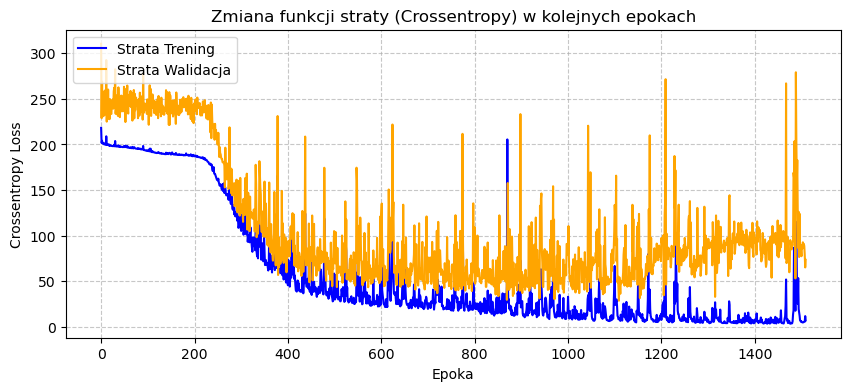

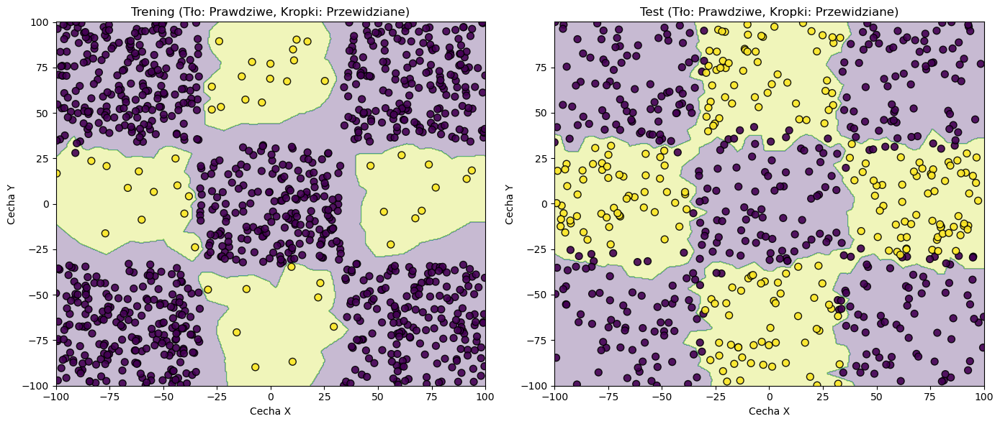

In [31]:
warstwa_1 = warstwa_liniowa(2, 10, 'xavier')
warstwa_2 = warstwa_liniowa(10, 5, 'xavier')
warstwa_3 = warstwa_liniowa(5, liczba_klas, 'xavier')
model = MLP((warstwa_1, tanh(), warstwa_2, tanh(), warstwa_3, softmax()), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9, l2_lambda=0.00001)
hist_train, hist_val, score = train(X_train, y_train, X_test, y_test, X_val, y_val, model, 10000, 64, funkcja_straty=Crossentropy, regresja=False, test=True, patience=400)